# Embeddings: from words to vectors, and what they are good for

Session 13 ended with the limits of word counts: "Spielzeug", "jouet" and "toy" share no column of a TF-IDF matrix. Language models represent text as dense vectors learned from huge amounts of unlabelled text in many languages. After this block you can

- explain tokens, embeddings, attention and pre-training at a conceptual level, and the difference between encoder, decoder and encoder–decoder models;
- load a model from the Hugging Face Hub and use it with the pattern tokeniser → model → outputs, or with `pipeline()`;
- use a sentence-embedding model for semantic search, clustering and as classification features, and compare each with TF-IDF on the EBTI decisions.

The notebook downloads several small models from the Hugging Face Hub on its first run (about 3.5 GB in total, cached afterwards in `~/.cache/huggingface/hub`): run it once before class. Most cells use only `intfloat/multilingual-e5-small` (about 470 MB). No API key is needed.

## Overview

| Section | What it covers |
|---|---|
| From words to vectors: tokens, embeddings, attention and pre-training | tokens and token counts per language, byte-pair encoding from scratch, `tiktoken` encodings, embeddings, cosine similarity, contextual embeddings, attention, pre-training |
| Encoder, decoder and encoder–decoder models | the three families and when to use which, inside the course model, the causal mask, fill-mask, text generation and translation with one model of each family |
| The Hugging Face pattern: Hub, tokeniser → model → outputs, `pipeline` | the Hub and model cards, the tokeniser step by step, model outputs and mean pooling, a classification head, `pipeline()` and zero-shot classification, reproducibility and licences |
| Embedding models (sentence-transformers) | sentence-embedding models, two multilingual models, encoding and comparing texts, inside `encode`, prefixes and a second model measured on the case study |
| Applications: semantic search, clustering and classification features | semantic search, retrieve and re-rank with a cross-encoder, BM25, clustering decisions, a t-SNE map, embedding features versus TF-IDF, a learning curve |
| Worked example | how often a new request finds its heading among similar decisions, within and across languages |
| Check your understanding, Exercises, Debrief | five questions, seven exercises in pairs, what to compare afterwards |

```mermaid
flowchart LR
    T["Text"] --> K["Tokeniser<br/>(subword tokens)"]
    K --> I["Token ids"]
    I --> E["Embedding lookup<br/>(one vector per token)"]
    E --> L["Transformer layers<br/>(attention)"]
    L --> C["Contextual vectors<br/>(one per token)"]
    C --> P1["Pooling: one vector per text<br/>(search, clustering, features)"]
    C --> P2["Next-token scores<br/>(text generation, Block 2)"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

Next we import the libraries used throughout and quieten progress bars and notices: the environment variable `HF_HUB_VERBOSITY` and `transformers.logging.set_verbosity_error()` keep only real errors. The models run on a GPU if PyTorch finds one (including Apple silicon), otherwise on the CPU.

In [2]:
import time
import warnings

os.environ["HF_HUB_VERBOSITY"] = "error"                      # no "unauthenticated requests" notice
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=FutureWarning)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from huggingface_hub.utils import disable_progress_bars

disable_progress_bars()
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
torch.manual_seed(0)
print("torch", torch.__version__, "| transformers", transformers.__version__)

torch 2.14.1 | transformers 5.19.0


## From words to vectors: tokens, embeddings, attention and pre-training

### Tokens

A language model does not read words. It reads **tokens** from a fixed vocabulary of typically 30,000 to 250,000 entries. Frequent words are one token ("plastic"); rare words and compounds are cut into pieces ("Kunststoffspielzeug" → "Kunststoff" + "spiel" + "zeug"). Single characters (or single bytes) are also in the vocabulary, so every string can be represented: unlike `CountVectorizer` in Session 13, there are no unknown words. The price is that one word can cost several tokens.

Three families of tokenisers are common:

- **Byte-pair encoding** (BPE; GPT-type models, Sennrich et al., 2016): start from single characters (or bytes) and repeatedly merge the most frequent neighbouring pair into a new token (built from scratch below).
- **WordPiece** (BERT): similar merges, chosen by how much they increase the likelihood of the training text; pieces inside a word are marked `##`.
- **SentencePiece/Unigram** (XLM-RoBERTa, multilingual-e5, T5): starts from a large vocabulary and removes the pieces that matter least; the start of a word is marked `▁`.

![The phrase 'plastic toy car with wheels' as 5 words, 6 SentencePiece tokens and 5 BPE tokens; the German 'Kunststoffspielzeugauto mit Rädern' as 3 words, 7 SentencePiece and 9 BPE tokens](../figures/tokenisation.png)

Why care? The input limit of a model (the **context window**), the price of an API call and the processing time are all counted in tokens, not words.

Next we load the course's embedding model and its tokeniser, and the BPE tokeniser of GPT-4o-type models from `tiktoken`. `SentenceTransformer(name)` downloads a model from the Hugging Face Hub once and caches it; `model.tokenizer.tokenize(text)` shows the token pieces; `enc.encode(text)` returns token ids and `enc.decode([id])` turns one id back into text.

*Predict before running:* into how many pieces will each tokeniser cut "Kunststoffspielzeug in Form eines Autos"?

In [3]:
import tiktoken
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("intfloat/multilingual-e5-small")   # about 470 MB, first run only; GPU if available
sp_tok = model.tokenizer                       # SentencePiece tokeniser of the model
gpt_tok = tiktoken.get_encoding("o200k_base")  # BPE tokeniser of GPT-4o-type models

for text in ["Kunststoffspielzeug in Form eines Autos", "plastic toy in the shape of a car"]:
    print(sp_tok.tokenize(text))
    print([gpt_tok.decode([i]) for i in gpt_tok.encode(text)])

['▁Kunststoff', 'spiel', 'zeug', '▁in', '▁Form', '▁eines', '▁Auto', 's']
['K', 'unst', 'stoff', 'spiel', 'zeug', ' in', ' Form', ' eines', ' Autos']
['▁plastic', '▁toy', '▁in', '▁the', '▁shape', '▁of', '▁a', '▁car']
['plastic', ' toy', ' in', ' the', ' shape', ' of', ' a', ' car']


Now the same on real descriptions: we count words and tokens of 2,000 EBTI decisions and compute characters per token for five languages. `Series.map(f)` applies a function to every text; `groupby(...).sum()` adds up per language.

In [4]:
decisions = pd.read_parquet("case-study/data/ebti/train_sample.parquet")
sample = decisions.sample(2000, random_state=0)
counts = pd.DataFrame({
    "language": sample["language"],
    "characters": sample["description"].str.len(),
    "words": sample["description"].str.split().str.len(),
    "e5_tokens": sample["description"].map(lambda t: len(sp_tok.tokenize(t))),
    "gpt_tokens": sample["description"].map(lambda t: len(gpt_tok.encode(t))),
})
print(counts[["words", "e5_tokens", "gpt_tokens"]].sum().to_dict())
per_lang = counts.groupby("language")[["characters", "gpt_tokens"]].sum()
print((per_lang["characters"] / per_lang["gpt_tokens"]).loc[["de", "fr", "en", "pl", "cs"]].round(1).to_dict())
print("share longer than the e5 input limit:", round((counts["e5_tokens"] > model.max_seq_length - 2).mean(), 3))

{'words': 197951, 'e5_tokens': 371634, 'gpt_tokens': 390454}
{'de': 3.7, 'fr': 3.9, 'en': 4.0, 'pl': 3.0, 'cs': 2.8}
share longer than the e5 input limit: 0.013


The descriptions need about two tokens per word. Polish and Czech need fewer characters per token than French or German, so the same content costs more tokens, and more money in an API that bills per token (Petrov et al., 2023, measured differences of up to about 15 times between languages). About 1 % of the descriptions exceed the model's input limit of 512 tokens.

> **Note.** Every model has its own tokeniser. `tiktoken` counts are exact only for OpenAI models; for other models use their own tokeniser or the token counts the API reports.

### Byte-pair encoding from scratch, on descriptions of goods

*Adapted from the [Hugging Face LLM Course, chapter 6, "Byte-Pair Encoding tokenization"](https://huggingface.co/learn/llm-course/chapter6/5) (Hugging Face, Apache-2.0); code from [extras/02-hf-course-bpe-tokenization.ipynb](extras/02-hf-course-bpe-tokenization.ipynb), applied to EBTI descriptions.*

Training a BPE tokeniser has four steps:

1. **Pre-tokenise**: split the corpus into words (GPT-2 splits at spaces and punctuation and writes a leading space as `Ġ`) and count each word.
2. **Base vocabulary**: all characters that occur.
3. **Merge**: count every pair of neighbouring symbols inside the words, weighted by word frequency; add the most frequent pair to the vocabulary as a new symbol and replace it everywhere.
4. Repeat step 3 until the vocabulary has the desired size. The ordered list of merges *is* the tokeniser: to tokenise new text, split it into characters and apply the merges in the order they were learned.

Next we pre-tokenise 300 English descriptions with the pre-tokeniser of GPT-2 (`backend_tokenizer.pre_tokenizer.pre_tokenize_str` returns words with their character offsets) and count the words with a `defaultdict(int)`.

In [5]:
from collections import defaultdict

from transformers import AutoTokenizer

gpt2_tok = AutoTokenizer.from_pretrained("openai-community/gpt2")     # only its pre-tokeniser is used
corpus = decisions.loc[decisions["language"] == "en", "description"].str.lower().head(300).tolist()

word_freqs = defaultdict(int)
for text in corpus:
    for word, offset in gpt2_tok.backend_tokenizer.pre_tokenizer.pre_tokenize_str(text):
        word_freqs[word] += 1
print(len(word_freqs), "distinct words; most frequent:", sorted(word_freqs.items(), key=lambda kv: -kv[1])[:8])

4283 distinct words; most frequent: [('.', 1398), ('Ċ', 912), (',', 832), ('Ġand', 640), ('Ġa', 638), ('Ġthe', 579), ('Ġof', 439), ('Ġis', 427)]


The base vocabulary is the sorted set of characters; every word starts as a list of single characters. `sorted(set(...))` collects the characters; a dict comprehension builds the splits.

In [6]:
alphabet = sorted({ch for word in word_freqs for ch in word})
vocab = ["<|endoftext|>"] + alphabet.copy()
splits = {word: list(word) for word in word_freqs}
print(len(alphabet), "base symbols:", "".join(alphabet[:60]))

100 base symbols: "#%&'()*+,-./0123456789:;<>@abcdefghijklmnopqrstuvwxyz~¡¢£¤¥


Two helper functions do the work: `compute_pair_freqs` counts neighbouring pairs, weighted by how often the word occurs, and `merge_pair` replaces one pair by its merged symbol in every word.

In [7]:
def compute_pair_freqs(splits):
    pair_freqs = defaultdict(int)
    for word, freq in word_freqs.items():
        split = splits[word]
        for i in range(len(split) - 1):
            pair_freqs[(split[i], split[i + 1])] += freq
    return pair_freqs


def merge_pair(a, b, splits):
    for word, split in splits.items():
        i = 0
        while i < len(split) - 1:
            if split[i] == a and split[i + 1] == b:
                split = split[:i] + [a + b] + split[i + 2:]
            else:
                i += 1
        splits[word] = split
    return splits

*Predict:* which pair of characters is the most frequent in English descriptions of goods? Next we run the merge loop until the vocabulary has 400 entries and print the first 15 merges. `max(d, key=d.get)` returns the key with the largest value.

In [8]:
merges = {}
while len(vocab) < 400:
    pair_freqs = compute_pair_freqs(splits)
    best = max(pair_freqs, key=pair_freqs.get)
    splits = merge_pair(*best, splits)
    merges[best] = best[0] + best[1]
    vocab.append(best[0] + best[1])
print(list(merges.items())[:15])
print("longest learned tokens:", sorted(vocab, key=len)[-8:])

[(('Ġ', 'a'), 'Ġa'), (('i', 'n'), 'in'), (('Ġ', 't'), 'Ġt'), (('Ġ', 'c'), 'Ġc'), (('h', 'e'), 'he'), (('Ġ', 'p'), 'Ġp'), (('o', 'n'), 'on'), (('r', 'e'), 're'), (('Ġ', 's'), 'Ġs'), (('e', 'r'), 'er'), (('i', 't'), 'it'), (('o', 'r'), 'or'), (('Ġ', 'f'), 'Ġf'), (('l', 'e'), 'le'), (('n', 'd'), 'nd')]
longest learned tokens: ['Ġproduct', 'Ġcontain', 'Ġplastic', 'Ġprocess', 'Ġprotein', 'Ġdisplay', 'Ġfunction', '<|endoftext|>']


Finally a tokeniser that applies the learned merges, in order, to new text. Words that were frequent in the corpus become single tokens; rare words fall apart into pieces.

In [9]:
def bpe_tokenize(text):
    words = [w for w, _ in gpt2_tok.backend_tokenizer.pre_tokenizer.pre_tokenize_str(text.lower())]
    pieces = [list(w) for w in words]
    for (a, b), merged in merges.items():
        for k, split in enumerate(pieces):
            i = 0
            while i < len(split) - 1:
                if split[i] == a and split[i + 1] == b:
                    split = split[:i] + [merged] + split[i + 2:]
                else:
                    i += 1
            pieces[k] = split
    return sum(pieces, [])


print(bpe_tokenize("Toy car of plastics, with wheels"))
print(bpe_tokenize("Kunststoffspielzeug"))

['to', 'y', 'Ġc', 'ar', 'Ġof', 'Ġplastic', 's', ',', 'Ġwith', 'Ġw', 'he', 'el', 's']
['k', 'un', 'st', 'st', 'o', 'f', 'f', 's', 'p', 'i', 'el', 'z', 'e', 'u', 'g']


Real tokenisers work on **bytes** rather than characters, so that any Unicode text (Greek, emoji) has a base symbol, and they train on billions of words with 50,000 to 200,000 merges. The principle is the same.

> 📖 **Read more:** [extras/02-hf-course-bpe-tokenization.ipynb](extras/02-hf-course-bpe-tokenization.ipynb) (Hugging Face course): the original code on a four-sentence corpus; the course chapter also explains WordPiece and Unigram.

### Encodings compared with tiktoken

*Adapted from the [OpenAI Cookbook, "How to count tokens with tiktoken"](https://cookbook.openai.com/examples/how_to_count_tokens_with_tiktoken) (OpenAI, MIT); code from [extras/03-openai-cookbook-count-tokens.ipynb](extras/03-openai-cookbook-count-tokens.ipynb).*

`tiktoken` ships the encodings of OpenAI's model generations: `r50k_base` (GPT-3), `p50k_base` (Codex), `cl100k_base` (GPT-3.5 and GPT-4) and `o200k_base` (GPT-4o and later). `tiktoken.encoding_for_model(name)` picks the right one for a model name. The encodings differ in how they split words, group spaces and handle non-English text and numbers.

`decode_single_token_bytes(id)` shows the bytes behind one token; decoding a single token to text can be lossy when a token ends in the middle of a multi-byte character (Greek, umlauts). Next we compare the four encodings on a German compound, a tariff code with a percentage, and a Greek phrase.

In [10]:
def compare_encodings(example):
    print(f'\n"{example}"')
    for name in ["r50k_base", "p50k_base", "cl100k_base", "o200k_base"]:
        enc = tiktoken.get_encoding(name)
        ids = enc.encode(example)
        print(f"{name:12s} {len(ids):3d} tokens  {[enc.decode_single_token_bytes(t) for t in ids][:12]}")


print(tiktoken.encoding_for_model("gpt-4o-mini").name)
compare_encodings("Kunststoffspielzeug")
compare_encodings("CN 6404 19 90, 85 % Baumwolle")
compare_encodings("Παιχνίδι αυτοκίνητο")

o200k_base

"Kunststoffspielzeug"
r50k_base      9 tokens  [b'K', b'un', b'st', b'st', b'off', b'sp', b'iel', b'ze', b'ug']
p50k_base      9 tokens  [b'K', b'un', b'st', b'st', b'off', b'sp', b'iel', b'ze', b'ug']
cl100k_base    6 tokens  [b'K', b'un', b'st', b'stoff', b'spiel', b'zeug']
o200k_base     5 tokens  [b'K', b'unst', b'stoff', b'spiel', b'zeug']

"CN 6404 19 90, 85 % Baumwolle"
r50k_base     13 tokens  [b'CN', b' 6', b'404', b' 19', b' 90', b',', b' 85', b' %', b' Ba', b'um', b'w', b'ol']
p50k_base     13 tokens  [b'CN', b' 6', b'404', b' 19', b' 90', b',', b' 85', b' %', b' Ba', b'um', b'w', b'ol']
cl100k_base   15 tokens  [b'CN', b' ', b'640', b'4', b' ', b'19', b' ', b'90', b',', b' ', b'85', b' %']
o200k_base    14 tokens  [b'CN', b' ', b'640', b'4', b' ', b'19', b' ', b'90', b',', b' ', b'85', b' %']

"Παιχνίδι αυτοκίνητο"
r50k_base     25 tokens  [b'\xce', b'\xa0', b'\xce\xb1', b'\xce\xb9', b'\xcf', b'\x87', b'\xce\xbd', b'\xce', b'\xaf', b'\xce', b'\xb4', b'\xce\xb9']

Newer encodings need fewer tokens for the same text, especially outside English: the vocabulary grew from about 50,000 to 200,000 entries. Numbers are split into short digit groups, which is one reason why language models are weak at arithmetic and at copying long codes exactly.

> 📖 **Read more:** [extras/03-openai-cookbook-count-tokens.ipynb](extras/03-openai-cookbook-count-tokens.ipynb) (OpenAI Cookbook): the same functions, plus counting the tokens of a chat request with several messages and with tool definitions (Block 2, costs).

### Embeddings

An **embedding** is a list of a few hundred real numbers that represents a token or a whole text, learned so that similar items get nearby vectors. A TF-IDF vector has one column per word and is mostly zeros; an embedding is **dense** and short, and its single numbers have no readable meaning. An analogy: a TF-IDF vector is a shopping list with one line per possible product; an embedding is a position on a map, where nearby places are similar.

Embeddings are learned from the **distributional hypothesis**: words that occur in similar contexts have similar meanings ("You shall know a word by the company it keeps", Firth, 1957). word2vec (Mikolov et al., 2013) learned one vector per word by predicting neighbouring words. **Multilingual** models are trained on many languages together, so "Spielzeug" and "jouet" end up close.

### Cosine similarity

Nearness of two embeddings is measured with **cosine similarity**: the dot product of two vectors divided by the product of their lengths, cos(a, b) = a·b / (‖a‖ ‖b‖). It depends only on the angle between the vectors, ranges from −1 to 1, and equals the plain dot product when both vectors have length 1. Worked example with made-up vectors toy = (0.9, 0.1, 0.3) and jouet = (0.8, 0.2, 0.4): a·b = 0.72 + 0.02 + 0.12 = 0.86, ‖toy‖ = 0.954, ‖jouet‖ = 0.917, so the cosine is 0.86 / 0.875 = 0.98.

Next we compute cosine similarity for the three made-up vectors and for two one-hot (bag-of-words) vectors. `a @ b` is the dot product and `np.linalg.norm(a)` the length of a vector.

In [11]:
def cosine(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))


toy, jouet, shoe = np.array([0.9, 0.1, 0.3]), np.array([0.8, 0.2, 0.4]), np.array([0.1, 0.9, 0.2])
print("toy-jouet", round(cosine(toy, jouet), 3), "| toy-shoe", round(cosine(toy, shoe), 3))
onehot = np.eye(3)                           # bag-of-words: one column per word
print("two different words as one-hot vectors:", cosine(onehot[0], onehot[1]))

toy-jouet 0.984 | toy-shoe 0.271
two different words as one-hot vectors: 0.0


In bag-of-words, "toy" and "jouet" are as different as "toy" and "shoe" (cosine 0). With embeddings, similarity becomes geometry, and "find similar decisions", "group decisions" and "use text as a feature" become standard operations on vectors (the applications section).

> **Note.** Embeddings inherit the patterns of their training text, including stereotypes (Bolukbasi et al., 2016, found "man is to computer programmer as woman is to homemaker" in word vectors trained on news). They also capture what a text is *about* more than fine details: leather and textile shoes are close in embedding space, although the tariff separates them.

### Contextual embeddings: one word, several meanings

word2vec gives "mouse" one vector, whether it is a computer mouse (heading 8471) or a plush toy (9503). A transformer gives every token a vector that depends on the whole sentence: a **contextual embedding**. Next we take the vector of the token `▁mouse` in three sentences. `model.encode(..., output_value="token_embeddings")` returns one vector per token instead of one per text; `convert_ids_to_tokens` tells us which position holds `▁mouse`.

In [12]:
def token_vector(sentence, piece="▁mouse"):
    vecs = model.encode(sentence, output_value="token_embeddings")
    tokens = sp_tok.convert_ids_to_tokens(sp_tok(sentence)["input_ids"])
    return vecs[tokens.index(piece)].cpu().numpy()


a = token_vector("passage: wireless mouse for a computer with USB receiver")
b = token_vector("passage: plush toy shaped like a mouse for children")
c = token_vector("passage: optical mouse with scroll wheel for laptops")
print("computer-toy", round(float(cosine(a, b)), 2), "| computer-computer", round(float(cosine(a, c)), 2))

computer-toy 0.92 | computer-computer 0.94


The two computer mice are closer to each other than to the toy mouse, although the word is the same. The difference is small for this model, because e5 was trained for good *sentence* vectors and its token vectors carry much of the whole sentence; the direction is the expected one.

### Attention

A **transformer** (Vaswani et al., 2017) turns the sequence of token vectors into contextual vectors, layer by layer. The key step is **attention**: each token's new vector is a weighted average of the vectors of all tokens in the text, with weights that say how relevant each other token is. In "the boot leaks because it cracked", the vector for "it" should take information from "boot". An analogy: in a meeting, everyone listens to everyone, but pays most attention to the people whose topic matches their own question.

Technically each token has a **query** (what it looks for), a **key** (what it offers) and a **value** (what it passes on), each computed from its vector with a learned matrix. The score of token *i* for token *j* is the dot product of query *i* and key *j*, divided by the square root of the vector size; a softmax turns each row of scores into weights that sum to 1. Real models run many such **heads** side by side in each of many layers.

![Illustrative attention weights for the sentence 'the boot leaks because it cracked'; the row for 'it' puts weight 0.61 on 'boot'](../figures/attention.png)

Next we compute attention for three tokens with two-dimensional vectors. `softmax` turns scores into weights; `Q @ K.T` gives all query–key scores at once; `A @ V` mixes the values.

*Predict:* the third query (1, 1) matches the first two keys equally well. What will its row of weights look like?

In [13]:
def softmax(z):
    e = np.exp(z - z.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


Q = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])   # queries: what each token looks for
K = np.array([[1.0, 0.0], [0.0, 1.0], [0.5, 0.5]])   # keys: what each token offers
V = np.array([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])   # values: what each token passes on
A = softmax(Q @ K.T / np.sqrt(2))                    # attention weights, one row per token
print(A.round(2))
print((A @ V).round(2))                              # new vector per token: weighted mix of values

[[0.46 0.22 0.32]
 [0.22 0.46 0.32]
 [0.33 0.33 0.33]]
[[2.73 3.73]
 [3.19 4.19]
 [3.   4.  ]]


> **Note.** Attention weights are tempting to read as explanations ("the model looked at 'boot'"), but they are not a reliable account of why a model decided something (Jain and Wallace, 2019). The figure illustrates the mechanism only.

### Pre-training

**Pre-training** teaches a model language before it sees any task, from unlabelled text alone:

- **masked language modelling** (BERT type): hide about 15 % of the tokens and predict them from both sides: "Schuhe mit Oberteil aus [MASK]" → "Leder" (the next section runs this);
- **next-token prediction** (GPT type): predict each token from all tokens before it: "shoes with uppers of" → "leather" (the next section and Block 2 run this).

After pre-training come further stages: **fine-tuning** on a smaller labelled dataset for one task; **contrastive training** on pairs of texts with the same meaning, which produces sentence-embedding models (the section on embedding models); **instruction tuning** of decoders on examples of instructions and good answers, so that they follow prompts (Block 2). Pre-training on text in about 100 languages is why one model can compare a Polish and a German description of goods without any labelled pairs.

## Encoder, decoder and encoder–decoder models

### The three families

Transformers come in three families, depending on which tokens attention may look at and what the model produces.

| Family | Attention | Pre-training | Output | Examples |
|---|---|---|---|---|
| **Encoder** (BERT type) | every token sees all tokens (bidirectional) | masked language modelling | one vector per token or per text | BERT, XLM-RoBERTa, multilingual-e5 |
| **Decoder** (GPT type) | every token sees only earlier tokens (causal) | next-token prediction | generated text, one token at a time | GPT, Claude, Llama, Qwen, Mistral |
| **Encoder–decoder** | encoder reads the input, decoder writes the output and attends to the encoder | reconstruct or transform text | a new text from an input text | T5, BART, Whisper, translation models |

```mermaid
flowchart TB
    subgraph ENC["Encoder (BERT type)"]
        direction LR
        e1["Schuhe aus [MASK]"] --> e2["bidirectional attention"] --> e3["vector per token: 'Leder'"]
    end
    subgraph DEC["Decoder (GPT type)"]
        direction LR
        d1["shoes with uppers of"] --> d2["causal attention"] --> d3["next token: 'leather'"]
    end
    subgraph ED["Encoder-decoder (T5 type)"]
        direction LR
        x1["Toy car of plastics"] --> x2["encoder"] --> x3["decoder"] --> x4["Spielzeugwagen aus Kunststoff"]
    end
```

Rules of thumb: an **encoder** when you need a representation of a text (classification, search, clustering); a **decoder** when you need to generate text or follow instructions; an **encoder–decoder** for mapping one text to another (translation, summarisation, speech to text). Large decoders can do all of these through prompting, at a higher cost. Many practical systems combine an encoder for search with a decoder for the answer (Session 15).

### Inside the course model

Next we look inside multilingual-e5-small. `print(model)` shows the modules of a sentence-transformers model; `model[0].auto_model` is the underlying transformer, and `p.numel()` counts the numbers in one weight matrix.

In [14]:
print(model)
enc = model[0].auto_model
print(type(enc).__name__, "| layers:", enc.config.num_hidden_layers, "| vector size:", enc.config.hidden_size,
      "| heads per layer:", enc.config.num_attention_heads)
n_all = sum(p.numel() for p in enc.parameters())
n_emb = enc.embeddings.word_embeddings.weight.numel()
print(f"{n_all / 1e6:.1f} million parameters, {n_emb / 1e6:.1f} million of them in the token-embedding table")

SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)
BertModel | layers: 12 | vector size: 384 | heads per layer: 12
117.7 million parameters, 96.0 million of them in the token-embedding table


multilingual-e5-small is a `BertModel`, an encoder: 12 layers, 384 numbers per vector. Most of its parameters sit in the table that holds one vector for each of its 250,000 tokens, the price of covering about 100 languages. It runs on a laptop; a decoder with billions of parameters needs a GPU server or a paid API (Block 2).

### The causal mask: what a decoder may see

The only structural difference between an encoder layer and a decoder layer is a **mask**: in a decoder, token *i* may not attend to tokens after it, because during generation those tokens do not exist yet. The mask sets the scores above the diagonal to minus infinity before the softmax, so their weights become 0. Next we apply it to four tokens with random queries and keys; `np.triu(..., k=1)` selects the entries above the diagonal.

In [15]:
rng = np.random.default_rng(0)
Qr, Kr = rng.normal(size=(4, 8)), rng.normal(size=(4, 8))
scores = Qr @ Kr.T / np.sqrt(8)
print("encoder (bidirectional):\n", softmax(scores).round(2))
causal = np.where(np.triu(np.ones((4, 4)), k=1) == 1, -np.inf, scores)
print("decoder (causal):\n", softmax(causal).round(2))

encoder (bidirectional):
 [[0.3  0.47 0.08 0.14]
 [0.33 0.07 0.25 0.35]
 [0.32 0.39 0.23 0.06]
 [0.1  0.03 0.68 0.18]]
decoder (causal):
 [[1.   0.   0.   0.  ]
 [0.83 0.17 0.   0.  ]
 [0.34 0.41 0.25 0.  ]
 [0.1  0.03 0.68 0.18]]


The first token of a decoder can only look at itself (weight 1.0); the last token sees everything. This is why a decoder can be trained on next-token prediction for all positions of a text at once, and why it can only generate left to right.

### One model of each family at work

*Adapted from the [Hugging Face LLM Course, chapter 1, "Transformers, what can they do?"](https://huggingface.co/learn/llm-course/chapter1/3) (Hugging Face, Apache-2.0); code from [extras/04-hf-course-transformer-pipelines.ipynb](extras/04-hf-course-transformer-pipelines.ipynb), with small models and customs examples.*

#### Encoder: fill-mask

A German BERT model predicts a hidden token from both sides, exactly its pre-training task. `pipeline("fill-mask", model=...)` wraps the model; `top_k` sets how many candidates to return. *Predict:* which material will it put into "Schuhe mit Oberteil aus [MASK] und Laufsohle aus Gummi"?

In [16]:
from transformers import pipeline

fill_mask = pipeline("fill-mask", model="google-bert/bert-base-german-cased", device="cpu")
print("mask token:", fill_mask.tokenizer.mask_token)
for r in fill_mask("Schuhe mit Oberteil aus [MASK] und Laufsohle aus Gummi.", top_k=3):
    print(f"{r['token_str']:12s} {r['score']:.2f}")

mask token: [MASK]


Leder        0.36
Kunststoff   0.13
Stoff        0.11


#### Decoder: text generation

A small instruction-tuned decoder, Qwen2.5-0.5B-Instruct (about 1 GB; Block 2 uses it again), continues a text one token at a time. `max_new_tokens` limits the length; `do_sample=False` always takes the most likely next token, so the output is repeatable.

In [17]:
generator = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct", device="cpu")
out = generator("Customs classification of footwear depends on", max_new_tokens=25, do_sample=False)
print(out[0]["generated_text"])

Customs classification of footwear depends on the following factors: ____.
A. Material
B. Size
C. Color
D. Shape
Answer:

AB


Read the continuation: the decoder simply continues the text in a style it has seen in training (here, apparently, a quiz). A decoder does not "answer" a question unless the input is formatted as a conversation it was instruction-tuned on; Block 2 shows these chat templates and why a small model's answers must be checked.

#### Encoder–decoder: translation

T5 (Raffel et al., 2020) was pre-trained to turn one text into another; the task is written in front of the input. In transformers 5 the generic text-to-text pipeline was removed, so we use the pattern of the next section directly: `AutoModelForSeq2SeqLM` loads an encoder–decoder model, and `generate` lets its decoder write the output.

In [18]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

t5_tok = AutoTokenizer.from_pretrained("google-t5/t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("google-t5/t5-small")
src = ["translate English to German: Toy car of plastics with wheels.",
       "translate English to French: Ladies' shoes with leather uppers and rubber soles."]
batch = t5_tok(src, return_tensors="pt", padding=True)
print(type(t5).__name__)
print(t5_tok.batch_decode(t5.generate(**batch, max_new_tokens=40), skip_special_tokens=True))

T5ForConditionalGeneration


['Spielzeugwagen aus Kunststoff mit Rädern.', 'Chaussures pour femmes avec dessus en cuir et semelles en caoutchouc.']


The course notebooks stop here; the Hugging Face course also shows named-entity recognition, question answering and summarisation with `pipeline()`. These models are general-purpose and small; check them on your own labelled examples before trusting them on customs texts.

> 📖 **Read more:** [extras/04-hf-course-transformer-pipelines.ipynb](extras/04-hf-course-transformer-pipelines.ipynb) (Hugging Face course): `pipeline()` for sentiment, zero-shot classification, generation, fill-mask, named entities, question answering, summarisation and translation. Without `model=` it downloads large default models; pass small ones.

## The Hugging Face pattern: Hub, tokeniser → model → outputs, `pipeline`

### The Hub and the model card

The [Hugging Face Hub](https://huggingface.co/models) hosts hundreds of thousands of open models. A model is identified by `organisation/name`. Its page, the **model card**, says what it was trained on, what it is for, its limits and its **licence** (Apache-2.0 and MIT allow commercial use, "NC" licences do not). `from_pretrained(name)` downloads the files once into the cache (`~/.cache/huggingface/hub`; the environment variable `HF_HOME` moves it) and loads them from there afterwards, also offline.

Next we read the model card's metadata. `model_info(name)` asks the Hub (it needs internet, so the cell catches a network error).

In [19]:
from huggingface_hub import model_info

name = "intfloat/multilingual-e5-small"
try:
    info = model_info(name)
    print(info.id, "| task:", info.pipeline_tag, "| licence:", info.card_data.get("license"))
    print("current commit:", info.sha)
except Exception as err:
    print("Hub not reachable:", type(err).__name__)

intfloat/multilingual-e5-small | task: sentence-similarity | licence: mit
current commit: 614241f622f53c4eeff9890bdc4f31cfecc418b3


### Tokeniser → model → outputs

Every model in `transformers` is used in the same three steps:

1. **Tokeniser.** `AutoTokenizer.from_pretrained(name)` loads the model's own tokeniser. Called on a list of texts with `padding=True, truncation=True, return_tensors="pt"`, it returns PyTorch tensors: `input_ids` (token ids) and `attention_mask` (1 for real tokens, 0 for padding).
2. **Model.** `AutoModel.from_pretrained(name)` reads the configuration and builds the right architecture; the `Auto` classes save you from knowing the class name.
3. **Outputs.** `model(**inputs)` passes the tensors as keyword arguments. `torch.no_grad()` switches off what is only needed for training. An encoder returns `last_hidden_state`, one vector per token.

```mermaid
flowchart LR
    T["Texts"] --> K["AutoTokenizer"] --> I["input_ids,<br/>attention_mask"] --> M["AutoModel..."] --> O["last_hidden_state<br/>or logits"] --> P["post-processing:<br/>pooling, softmax, id2label"]
```

Next we run step 1 on two descriptions.

In [20]:
from transformers import AutoModel

tokenizer = AutoTokenizer.from_pretrained(name)
texts = ["query: Damenschuhe mit Oberteil aus Leder", "query: Voiture jouet en matière plastique, avec roues"]
inputs = tokenizer(texts, padding=True, truncation=True, return_tensors="pt")
print(list(inputs.keys()), inputs["input_ids"].shape)          # 2 texts, padded to the same length
print(tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))  # <s> ... </s> <pad>
print(inputs["attention_mask"])

['input_ids', 'attention_mask'] torch.Size([2, 16])
['<s>', '▁que', 'ry', ':', '▁Damen', 'schuhe', '▁mit', '▁Ober', 'teil', '▁aus', '▁Leder', '</s>', '<pad>', '<pad>', '<pad>', '<pad>']
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


#### Step 1 in detail: inside the tokeniser

*Adapted from the [Hugging Face LLM Course, chapter 2, "Tokenizers"](https://huggingface.co/learn/llm-course/chapter2/4) (Hugging Face, Apache-2.0); code from [extras/01-hf-course-tokenizers.ipynb](extras/01-hf-course-tokenizers.ipynb).*

Calling a tokeniser does two things in one go: **encoding** (text → tokens → ids) and adding the **special tokens** the model expects. The two halves are also available separately: `tokenize` splits the text into tokens, `convert_tokens_to_ids` looks them up in the vocabulary, and `decode` turns ids back into text. A tokeniser is saved and loaded like a model with `save_pretrained(folder)`.

In [21]:
sequence = "Damenstiefel mit Oberteil aus Rindleder"
tokens = tokenizer.tokenize(sequence)
ids = tokenizer.convert_tokens_to_ids(tokens)
print(tokens)
print(ids)
print(tokenizer(sequence)["input_ids"])          # the same ids, with special tokens at both ends
print(tokenizer.decode(ids), "|", tokenizer.decode(tokenizer(sequence)["input_ids"]))
print("vocabulary size:", tokenizer.vocab_size, "| special tokens:", tokenizer.all_special_tokens)

['▁Damen', 's', 'tie', 'fel', '▁mit', '▁Ober', 'teil', '▁aus', '▁Rin', 'd', 'leder']
[170936, 7, 2061, 7510, 491, 32629, 35617, 1312, 39668, 71, 25389]
[0, 170936, 7, 2061, 7510, 491, 32629, 35617, 1312, 39668, 71, 25389, 2]
Damenstiefel mit Oberteil aus Rindleder | <s> Damenstiefel mit Oberteil aus Rindleder</s>
vocabulary size: 250002 | special tokens: ['<s>', '</s>', '<unk>', '<pad>', '<mask>']


Next we save the tokeniser into a temporary folder (never into the repository) and list the files: the vocabulary and the rules, plus a configuration. `tempfile.TemporaryDirectory()` deletes the folder at the end of the `with` block.

In [22]:
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    tokenizer.save_pretrained(tmp)
    print(sorted(p.name for p in Path(tmp).iterdir()))
    reloaded = AutoTokenizer.from_pretrained(tmp)
    print(reloaded.tokenize(sequence) == tokens)

['tokenizer.json', 'tokenizer_config.json']


True


> 📖 **Read more:** [extras/01-hf-course-tokenizers.ipynb](extras/01-hf-course-tokenizers.ipynb) (Hugging Face course): the same steps with an English BERT tokeniser.

#### Steps 2 and 3: the model, its outputs and mean pooling

Next we pass the two tokenised descriptions of step 1 to the model and post-process its output. To get one vector per text we average the vectors of the real tokens (**mean pooling**, with the attention mask so that padding is ignored) and scale the result to length 1 with `torch.nn.functional.normalize`.

In [23]:
encoder = AutoModel.from_pretrained(name)
with torch.no_grad():
    outputs = encoder(**inputs)
print(type(outputs).__name__, outputs.last_hidden_state.shape)    # (texts, tokens, 384)

mask = inputs["attention_mask"].unsqueeze(-1)                     # (texts, tokens, 1)
pooled = (outputs.last_hidden_state * mask).sum(dim=1) / mask.sum(dim=1)
manual = torch.nn.functional.normalize(pooled, dim=-1)
print(manual.shape, "cosine of the two texts:", round(float(manual[0] @ manual[1]), 4))

BaseModelOutputWithPoolingAndCrossAttentions torch.Size([2, 16, 384])
torch.Size([2, 384]) cosine of the two texts: 0.7745


### A classification head: logits, softmax and labels

A model fine-tuned for classification has a small extra layer on top of the encoder. It is loaded with `AutoModelForSequenceClassification` and returns **logits**, one score per class; softmax turns them into probabilities, and `model.config.id2label` maps class numbers to names. The example model was fine-tuned on English film reviews (SST-2), so we give it English product reviews. The last line does the same in one call with `pipeline("sentiment-analysis")`, the shortcut of the next subsection.

In [24]:
from transformers import AutoModelForSequenceClassification

clf_name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
clf_tok = AutoTokenizer.from_pretrained(clf_name)
clf_model = AutoModelForSequenceClassification.from_pretrained(clf_name)
reviews = ["The shoes arrived broken.", "Great quality toy car, my son loves it."]
with torch.no_grad():
    logits = clf_model(**clf_tok(reviews, padding=True, return_tensors="pt")).logits
print(logits.round(decimals=2), logits.softmax(dim=-1).round(decimals=4), clf_model.config.id2label, sep="\n")
print(pipeline("sentiment-analysis", model=clf_name, device="cpu")(reviews))

tensor([[ 4.1500, -3.3800],
        [-4.2800,  4.5700]])
tensor([[9.9950e-01, 5.0000e-04],
        [1.0000e-04, 9.9990e-01]])
{0: 'NEGATIVE', 1: 'POSITIVE'}


[{'label': 'NEGATIVE', 'score': 0.9994667172431946}, {'label': 'POSITIVE', 'score': 0.9998573064804077}]


### The shortcut: `pipeline()`

`pipeline(task, model=name)` bundles tokeniser, model and post-processing for one task. Common task names: `"sentiment-analysis"`, `"zero-shot-classification"`, `"fill-mask"`, `"feature-extraction"`, `"text-generation"`. Always pass `model=`; without it, the library picks a default that can change between versions.

#### Zero-shot classification

**Zero-shot classification** needs no training data: a model trained on natural-language inference checks, for each candidate label, whether the text supports the sentence "This product is {label}." The multilingual model below reads German and French descriptions with English labels.

In [25]:
zero_shot = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli", device="cpu")
descriptions = ["Damenstiefel mit Oberteil aus Rindleder und Laufsohle aus Gummi",
                "Voiture jouet en matière plastique, avec roues",
                "Kabellose Laptop-Maus mit USB-Empfänger"]
labels = ["footwear", "toys", "computer equipment", "clothing"]
for r in zero_shot(descriptions, candidate_labels=labels, hypothesis_template="This product is {}."):
    print(f"{r['labels'][0]:20s} {r['scores'][0]:.2f}  {r['sequence']}")

footwear             0.92  Damenstiefel mit Oberteil aus Rindleder und Laufsohle aus Gummi
toys                 0.94  Voiture jouet en matière plastique, avec roues
computer equipment   0.90  Kabellose Laptop-Maus mit USB-Empfänger


> **Note.** A pipeline hides the tokeniser and the model, but not their limits: the zero-shot model knows only the labels you give it and needs one model call per label and text (1,229 headings would mean 1,229 calls per description), and every model cuts long texts at its input limit. Check a new pipeline on labelled examples before you trust it.

### Reproducibility: versions, cache and licences

A model repository on the Hub changes over time. `from_pretrained(name, revision="<commit hash>")` pins one version, so a result can be reproduced next year; without `revision` you get whatever the main branch held on the day of the first download. Record the model name, the commit, the library versions and the prefixes with every result, as for any other dependency.

Next we load the e5 tokeniser at the exact commit printed above and check the cache folder. `huggingface_hub.constants.HF_HUB_CACHE` is the cache path.

In [26]:
from huggingface_hub import constants

pinned = AutoTokenizer.from_pretrained(name, revision="614241f622f53c4eeff9890bdc4f31cfecc418b3")
print(pinned.tokenize(sequence) == tokens)
print("cache folder:", constants.HF_HUB_CACHE.replace(str(Path.home()), "~"))

True
cache folder: ~/.cache/huggingface/hub


> **Note.** Read the licence on the model card before a model goes into a project: the models of this notebook are MIT or Apache-2.0, but many models on the Hub are for non-commercial use only, and some decoders have their own community licences with conditions.

## Embedding models (sentence-transformers)

### Sentence-embedding models

A **sentence-embedding model** maps a whole text to one vector so that texts with similar meaning get a high cosine similarity. Sentence-BERT (Reimers and Gurevych, 2019) takes a pre-trained encoder, mean-pools its token vectors (as in the Hugging Face pattern above) and fine-tunes it on millions of pairs of texts that mean the same (questions and answers, translations), so that paired texts move together and unrelated texts apart (**contrastive training**). The `sentence-transformers` library wraps tokeniser, model, pooling and normalisation into one `encode` call.

### Two small multilingual models

Two small multilingual models fit the case study:

| Model | Vector size | Input limit | Notes |
|---|---|---|---|
| `intfloat/multilingual-e5-small` (Wang et al., 2024) | 384 | 512 tokens | needs a prefix: `"query: "` for search queries, `"passage: "` for stored documents |
| `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` | 384 | 128 tokens | no prefix, but cuts long descriptions |

Larger models are compared on the MTEB benchmark (Muennighoff et al., 2023).

### Encoding texts and comparing them

Next we embed five short texts with `model.encode(texts, normalize_embeddings=True)`; because the vectors then have length 1, `E @ E.T` holds all pairwise cosine similarities. For comparison we compute TF-IDF cosine similarities of the first text with the others.

*Predict:* will the German toy car be closer to the French toy car or to the German shoes?

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sents = ["Spielzeugauto aus Kunststoff, mit Rädern", "Voiture jouet en matière plastique, avec roues",
         "Toy car of plastics with wheels", "Damenschuhe mit Oberteil aus Leder", "Ladies' shoes with leather uppers"]
E = model.encode(["passage: " + s for s in sents], normalize_embeddings=True)
print(E.shape)
print((E @ E.T).round(2))
print("TF-IDF, first text:", cosine_similarity(TfidfVectorizer().fit_transform(sents)).round(2)[0])

(5, 384)
[[1.   0.94 0.91 0.86 0.81]
 [0.94 1.   0.91 0.83 0.82]
 [0.91 0.91 1.   0.77 0.8 ]
 [0.86 0.83 0.77 1.   0.9 ]
 [0.81 0.82 0.8  0.9  1.  ]]
TF-IDF, first text: [1.  0.  0.  0.3 0. ]


The three toy cars are closer to each other than to the shoes, across three languages; with TF-IDF the German toy car resembles only the German shoes, through "aus" and "mit". Note the narrow range: for e5, unrelated texts still score around 0.8. Compare similarities with each other, never with a fixed threshold such as 0.5.

> **Note.** Text beyond the input limit is cut off silently (`model.max_seq_length`). Forgetting the e5 prefixes raises no error; the model card asks for them, and whether leaving them out costs quality on your task has to be measured (measured below). Query and documents must be embedded with the same model: vectors of different models live in different spaces, and comparing them gives meaningless numbers without an error.

### Inside `encode`, and the utility functions

`encode` does exactly the mean pooling we computed by hand in the Hugging Face pattern. `model.similarity(A, B)` (or `sentence_transformers.util.cos_sim`) computes all pairwise cosine similarities, and `util.semantic_search(queries, corpus, top_k=k)` returns the top-k hits per query as dictionaries with `corpus_id` and `score`.

In [28]:
from sentence_transformers import util

E_q = model.encode("query: Damenschuhe mit Oberteil aus Leder", normalize_embeddings=True)
print("same as manual pooling:", np.allclose(E_q, manual[0].numpy(), atol=1e-5))
print(model.similarity(E[:2], E[2:]))
print(util.semantic_search(model.encode(["query: leather boots for women"], normalize_embeddings=True),
                           E, top_k=2))

same as manual pooling: True
tensor([[0.9136, 0.8593, 0.8116],
        [0.9108, 0.8297, 0.8186]])
[[{'corpus_id': 4, 'score': 0.8665857315063477}, {'corpus_id': 3, 'score': 0.8408687114715576}]]


### Do the prefixes matter, and does another model do better?

The e5 authors trained the model with `"query: "` and `"passage: "` in front of the texts. Next we measure what forgetting them costs, and compare with the MiniLM model of the table above, on a retrieval task from the case study: for 500 decisions of the validation set (`val.parquet`), is the true heading among the headings of the 5 most similar of 2,000 training decisions (**hit@5**)? The helper `hit_at_5` takes the two matrices of normalised vectors.

In [29]:
valid_all = pd.read_parquet("case-study/data/ebti/val.parquet")
small_tr = decisions.sample(2_000, random_state=1)
small_va = valid_all.sample(500, random_state=1)


def hit_at_5(E_docs, E_queries):
    top = np.argsort(-(E_queries @ E_docs.T), axis=1)[:, :5]
    heads = small_tr["heading"].to_numpy()
    return np.mean([h in heads[r] for h, r in zip(small_va["heading"], top)])


def enc(m, texts, prefix=""):
    return m.encode((prefix + texts).tolist(), batch_size=64, normalize_embeddings=True)

Three runs: e5 with prefixes, e5 without, and MiniLM (no prefix, input limit 128 tokens). This cell takes up to a minute on a laptop CPU.

In [30]:
minilm = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
d, q = small_tr["description"], small_va["description"]
results = {
    "e5 with prefixes": hit_at_5(enc(model, d, "passage: "), enc(model, q, "query: ")),
    "e5 without prefixes": hit_at_5(enc(model, d), enc(model, q)),
    "MiniLM (128 tokens)": hit_at_5(enc(minilm, d), enc(minilm, q)),
}
print({k: round(float(v), 3) for k, v in results.items()}, "| MiniLM limit:", minilm.max_seq_length)

{'e5 with prefixes': 0.668, 'e5 without prefixes': 0.676, 'MiniLM (128 tokens)': 0.588} | MiniLM limit: 128


Compare the three numbers yourself: differences of a few points on 500 queries are within noise (the standard error of a share near 0.65 is about 0.02); a larger gap is a reason to choose. Here the prefixes make no measurable difference, while MiniLM, which cuts the descriptions at 128 tokens, finds the heading less often. A model choice should be made on your own data and task like this, not from a general benchmark alone.

## Applications: semantic search, clustering and classification features

### Encoding the decisions once

We now embed 10,000 training decisions from the sample and 2,000 decisions of the validation set (`val.parquet`, as in Session 13), and use the vectors for three tasks, each compared with TF-IDF on the same decisions. Encoding is the expensive step: about half a minute here. In a project, save the vectors with `np.save` together with the model name and prefix, and encode only once.

```mermaid
flowchart LR
    R["Decisions<br/>(23 languages)"] --> M["Embedding model<br/>(encode once)"]
    M --> E[("Vectors<br/>12,000 x 384")]
    E --> S["Semantic search"]
    E --> C["Clustering"]
    E --> F["Classifier features"]
    Q["Query in any language"] --> M2["same model"] --> S
```

Next cell: the split and the encoding. `time.perf_counter()` measures the seconds.

In [31]:
train = decisions.sample(10_000, random_state=0)
valid = valid_all.sample(2_000, random_state=0)

t0 = time.perf_counter()
E_tr = model.encode(("passage: " + train["description"]).tolist(), batch_size=64, normalize_embeddings=True)
E_va = model.encode(("query: " + valid["description"]).tolist(), batch_size=64, normalize_embeddings=True)
print(E_tr.shape, E_va.shape, f"{time.perf_counter() - t0:.0f} s")

(10000, 384) (2000, 384) 33 s


### Semantic search

**Semantic search** retrieves documents by meaning instead of shared words, in two phases:

1. **Indexing** (once): embed every document and store the vectors.
2. **Querying** (per request): embed the query with the same model, compute its cosine similarity with every document vector and return the *k* most similar (**top-k**).

With vectors of length 1, step 2 is one matrix–vector product. For millions of documents, **approximate nearest-neighbour** indexes (for example FAISS) find the top-k without comparing the query with every vector. **Keyword search** with TF-IDF works the same way with sparse vectors, but only finds documents that share words with the query.

Next we search the German decisions with English queries, with embeddings and with TF-IDF. `np.argsort(-scores)[:k]` gives the positions of the *k* highest scores.

In [32]:
german = (train["language"] == "de").to_numpy()
tfidf = TfidfVectorizer(min_df=2, sublinear_tf=True).fit(train["description"])
T_de, heads_de = tfidf.transform(train["description"][german]), train["heading"].to_numpy()[german]


def search(query, k=5):
    q = model.encode("query: " + query, normalize_embeddings=True)
    for method, scores in [("embedding", E_tr[german] @ q),
                           ("tf-idf", (T_de @ tfidf.transform([query]).T).toarray().ravel())]:
        top = np.argsort(-scores)[:k]
        print(f"{method:10s}", [(heads_de[i], round(float(scores[i]), 2)) for i in top])


search("toys for children")
search("disposable face masks")

embedding  [('9503', 0.83), ('9503', 0.82), ('6111', 0.82), ('9503', 0.82), ('9503', 0.82)]
tf-idf     [('9504', 0.06), ('4011', 0.06), ('3907', 0.0), ('2935', 0.0), ('2106', 0.0)]
embedding  [('6307', 0.81), ('6307', 0.8), ('6307', 0.8), ('6307', 0.8), ('3808', 0.8)]
tf-idf     [('3907', 0.0), ('2935', 0.0), ('2106', 0.0), ('7308', 0.0), ('9031', 0.0)]


The English query "toys for children" finds German toy decisions (heading 9503) with embeddings; TF-IDF finds almost nothing, because the query shares no word with German text. A customs officer can thus see how other member states classified similar goods, whatever their language. Keyword search stays useful for exact terms (product codes, brand names, chemical numbers), so practical systems often combine both (**hybrid search**, Session 15).

### Retrieve and re-rank, and BM25

*Adapted from the sentence-transformers example ["Retrieve & Re-Rank over Simple Wikipedia"](https://github.com/huggingface/sentence-transformers/blob/main/examples/sentence_transformer/applications/retrieve_rerank/retrieve_rerank_simple_wikipedia.ipynb) (UKP Lab / Hugging Face, Apache-2.0), code in [extras/05-sbert-retrieve-rerank-wikipedia.ipynb](extras/05-sbert-retrieve-rerank-wikipedia.ipynb), on English EBTI decisions instead of Wikipedia.*

The embedding model of the semantic search above is a **bi-encoder**: query and document are encoded separately, which is fast because the documents are encoded once. A **cross-encoder** reads query and document *together* and outputs one relevance score; it is more accurate but must run once per pair, so it cannot search a large collection. The standard combination is **retrieve and re-rank**: the bi-encoder retrieves 32 candidates, the cross-encoder re-orders them. Lexical search with **BM25** (a refined TF-IDF score, implemented in `rank_bm25`) is shown alongside.

The cross-encoder `cross-encoder/ms-marco-MiniLM-L6-v2` was trained on English web search, so we search the English decisions only. Next we build the three indexes. `BM25Okapi` takes a list of token lists; the tokeniser lower-cases, strips punctuation and drops English stop words.

In [33]:
import string

from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

english = decisions[decisions["language"] == "en"].reset_index(drop=True)
passages = english["description"].str.slice(0, 600).tolist()
E_en = model.encode(["passage: " + p for p in passages], batch_size=64, normalize_embeddings=True)


def bm25_tokenizer(text):
    words = (w.strip(string.punctuation) for w in text.lower().split())
    return [w for w in words if w and w not in ENGLISH_STOP_WORDS]


bm25 = BM25Okapi([bm25_tokenizer(p) for p in passages])
cross_encoder = CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2", device="cpu")
print(len(passages), "English decisions indexed")

462 English decisions indexed


The search function prints the top 3 of each method with heading and the start of the description. `cross_encoder.predict(pairs)` scores a list of `[query, passage]` pairs.

In [34]:
def show(title, ids, scores):
    print(" ", title)
    for i, s in zip(ids, scores):
        print(f"    {s:6.2f}  {english['heading'][i]}  {passages[i][:70]!r}")


def search_rerank(query, top_k=32):
    print("QUERY:", query)
    bm = bm25.get_scores(bm25_tokenizer(query))
    show("BM25", np.argsort(-bm)[:3], np.sort(bm)[::-1][:3])
    sims = E_en @ model.encode("query: " + query, normalize_embeddings=True)
    hits = np.argsort(-sims)[:top_k]
    show("bi-encoder", hits[:3], sims[hits[:3]])
    ce = cross_encoder.predict([[query, passages[i]] for i in hits])
    order = np.argsort(-ce)[:3]
    show("re-ranked by the cross-encoder", hits[order], ce[order])


search_rerank("bicycle helmet for children")
search_rerank("wireless computer mouse")

QUERY: bicycle helmet for children
  BM25
      4.95  1704  'Bear Shaped Gums with Fibre\nWhat the product does or what it is used f'
      4.74  9503  'Colour Changing Abacus. The multicoloured beads change to white as chi'
      4.08  9503  'A pop-up play tent for children.    Made from breathable mesh and poly'
  bi-encoder
      0.83  9503  'Child’s Balance Bike. \n\nThis is a balance bike that enables a child to'
      0.83  6802  'A HEADSTONE MADE OF POLISHED, BEVELLED GRANITE, IN THE SHAPE OF A MOTO'
      0.82  1704  'Bear shaped multivitamin Gums/Jellies\nMultivitamins specially formulat'


  re-ranked by the cross-encoder
      3.04  9503  'Child’s Balance Bike. \n\nThis is a balance bike that enables a child to'
     -0.95  9503  "The 6-in-1 Trike is a young children's tricycle with a detachable pare"
     -6.78  9503  'A pop-up play tent for children.    Made from breathable mesh and poly'
QUERY: wireless computer mouse
  BM25
      6.95  8471  '"All-in-one" Desktop Computer. \n\nIt incorporates a 24” 4.5k retina dis'
      5.88  8536  'A WIRELESS RECEIVER WITH RELAY SWITCH FOR OPENING DOORS.'
      5.46  8518  'Bluetooth Wireless Earphones.  They come with a built-in microphone an'
  bi-encoder
      0.83  8471  '"All-in-one" Desktop Computer. \n\nIt incorporates a 24” 4.5k retina dis'
      0.83  8471  'THIS DEVICE IS A PORTABLE 13-INCH TOUCH SCREEN LED DISPLAY, AUTOMATIC '
      0.83  8471  'THIS IS A PORTABLE ADP MACHINE WHICH ALLOWS THE USER TO EXECUTE COMPUT'


  re-ranked by the cross-encoder
     -0.39  8471  '"All-in-one" Desktop Computer. \n\nIt incorporates a 24” 4.5k retina dis'
     -1.41  8471  'Portable ADP Machine (Tablet).\n\nIt is a handheld computing device with'
     -1.47  8471  'Portable ADP Machine (Tablet).\n\nIt is a handheld computing device with'


Read the three lists for each query. BM25 needs the exact words: "children" finds gummy bears, an abacus and a play tent, "computer" and "wireless" find a desktop computer, a door receiver and earphones. The bi-encoder finds texts on related topics, with scores so close (0.82 to 0.83) that they hardly separate a balance bike from a headstone. The cross-encoder scores each pair directly; its scores are not cosines, and low (negative) scores mean "probably not relevant": it puts the child's balance bike clearly first. No English decision in this sample describes a bicycle helmet, and the only one that mentions a mouse is the all-in-one desktop computer at the top of all three lists, so all methods return near misses: search always returns the most similar documents, even when none is relevant, and a threshold on the cross-encoder score could say "nothing found". Session 15 evaluates re-ranking with a labelled test set instead of by eye.

> 📖 **Read more:** [extras/05-sbert-retrieve-rerank-wikipedia.ipynb](extras/05-sbert-retrieve-rerank-wikipedia.ipynb) (sentence-transformers): the original over Simple English Wikipedia, with twelve example questions. Upstream bug: the search function moves the query to the GPU when *no* GPU is available; delete those two lines before running it on a laptop.

### Clustering decisions

Clustering on embeddings uses the methods of Session 11: normalise the vectors (then Euclidean distance and cosine similarity rank pairs identically), run k-means for a few values of *k*, then **describe** each cluster by its most frequent heading and language, and **look** at it in two dimensions. A 2-D UMAP picture of 1,500 decisions shows both forces at work: colour by chapter (left) gives groups of goods, colour by language (right) shows that German decisions form their own islands.

![UMAP projection of 1,500 decisions from five chapters: German decisions form one island per chapter, while French, English and other languages share a separate region that is still partly ordered by chapter](../figures/embedding_space.png)

Next we cluster the footwear decisions (chapter 64) into six groups. `silhouette_score` measures how well separated the clusters are; `adjusted_rand_score` compares the clusters with the headings (1 = identical, 0 = chance). `pd.crosstab` counts clusters against languages.

In [35]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

shoes = (train["chapter"] == "64").to_numpy()
km = KMeans(n_clusters=6, n_init=10, random_state=0).fit(E_tr[shoes])
print(shoes.sum(), "footwear decisions | silhouette", round(silhouette_score(E_tr[shoes], km.labels_), 3),
      "| ARI with headings", round(adjusted_rand_score(train["heading"][shoes], km.labels_), 2))
part = train[shoes].assign(cluster=km.labels_)
lang = part["language"].where(part["language"].isin(["de", "fr", "en", "cs"]), "other")
print(pd.crosstab(part["cluster"], lang))
print("most frequent heading:", part.groupby("cluster")["heading"].agg(lambda h: h.value_counts().index[0]).to_dict())

381 footwear decisions | silhouette 0.137 | ARI with headings 0.16
language  cs  de  en  fr  other
cluster                        
0          0  62   0   0      0
1          0  72   0   0      0
2          0  95   0   0      0
3          0  76   0   0      0
4          4   0   1  41      6
5          0   0   0   0     24
most frequent heading: {0: '6402', 1: '6403', 2: '6403', 3: '6404', 4: '6403', 5: '6405'}


The German decisions split by goods (one cluster is mostly slippers with textile uppers, heading 6404, another sandals), while the other languages form clusters of their own (one mostly French, one of Italian and other descriptions). Next we name the clusters by their most **distinctive words**: the mean TF-IDF weight of a word inside the cluster divided by its mean over all footwear decisions (words in fewer than five decisions of the cluster are ignored).

In [36]:
words = TfidfVectorizer(min_df=3).fit(part["description"])
W, names = words.transform(part["description"]), words.get_feature_names_out()
overall = np.asarray(W.mean(axis=0)).ravel()
for c in range(6):
    in_c = (km.labels_ == c)
    lift = np.asarray(W[in_c].mean(axis=0)).ravel() / (overall + 1e-9)
    lift[np.asarray((W[in_c] > 0).sum(axis=0)).ravel() < 5] = 0
    print(c, in_c.sum(), list(names[np.argsort(-lift)[:5]]))

0 62 ['sandalen', '9910', 'sandale', '9931', 'strasssteinen']
1 72 ['abstehenden', 'haken', 'hinten', '9111', '9113']
2 95 ['9993', '9998', '9996', '9950', 'wahr']
3 76 ['weichem', 'labilem', 'pantoffeln', 'gerautes', 'hausschuhe']
4 52 ['de', 'en', 'est', 'et', 'matière']
5 24 ['da', 'materiale', 'tessile', 'di', 'costituita']


With multilingual data, cross-tabulate clusters against `language` before you call them product groups, and choose *k* by whether the clusters are useful when you read them, not by the silhouette score alone. BERTopic (Grootendorst, 2022) builds topic models in this way (embeddings, UMAP, density-based clustering, class-based TF-IDF to name the clusters).

> 📖 **Read more:** the scikit-learn example in Session 13, [extras/05-sklearn-document-clustering-lsa.ipynb](../../13-classical-nlp/workbooks/extras/05-sklearn-document-clustering-lsa.ipynb), clusters documents with TF-IDF and LSA vectors instead of neural embeddings, with several clustering metrics.

### A 2-D map of the clusters with t-SNE

*Adapted from the [OpenAI Cookbook, "K-means Clustering in Python using OpenAI"](https://cookbook.openai.com/examples/clustering) (OpenAI, MIT), code in [extras/06-openai-cookbook-clustering.ipynb](extras/06-openai-cookbook-clustering.ipynb), with EBTI footwear decisions and e5 vectors instead of food reviews and OpenAI embeddings.*

**t-SNE** places points in two dimensions so that close neighbours in the 384-dimensional space stay close; distances between far-apart groups and the sizes of groups in the picture mean little. `perplexity` roughly sets how many neighbours each point considers. Next we draw the footwear decisions coloured by cluster, with a cross at each cluster's mean position.

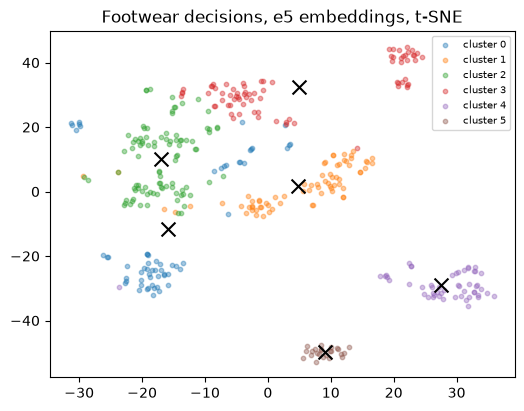

In [37]:
from sklearn.manifold import TSNE

xy = TSNE(n_components=2, perplexity=15, random_state=42, init="random", learning_rate=200).fit_transform(E_tr[shoes])
fig, ax = plt.subplots(figsize=(6, 4.5))
for c in range(6):
    pts = xy[km.labels_ == c]
    ax.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.4, label=f"cluster {c}")
    ax.scatter(*pts.mean(axis=0), marker="x", s=100, color="black")
ax.set_title("Footwear decisions, e5 embeddings, t-SNE")
ax.legend(fontsize=7, loc="best")
plt.show()

The OpenAI Cookbook then asks a generative model what five sample texts of each cluster have in common, to name the clusters. Block 2 introduces the API call that does this; trying it on these clusters is a good exercise once you have worked through Block 2.

> 📖 **Read more:** [extras/06-openai-cookbook-clustering.ipynb](extras/06-openai-cookbook-clustering.ipynb) (OpenAI Cookbook): k-means and t-SNE on 1,000 food reviews, and cluster naming with GPT-4 (needs an OpenAI key).

### Embedding features versus TF-IDF

Embeddings can replace the TF-IDF matrix as input to any classifier: each description becomes 384 numbers, and the linear model of Session 13 learns one weight per number and heading. The embedding model stays **frozen**; only the classifier is trained (fine-tuning the whole model belongs to module 3.4). A fair comparison uses the same decisions, split and classifier:

| Representation | Size | Knows translations? | Sees one decisive word? | Cost |
|---|---|---|---|---|
| TF-IDF words | about 35,000 columns (sparse) | no | yes, one column per word | very low |
| e5 embeddings | 384 (dense) | yes | weakly, averaged into 384 numbers | encoding time |
| both side by side | about 35,000 + 384 | yes | yes | both |

*Predict:* with 10,000 training decisions, which wins?

Next we train the same linear SVM on embeddings, on TF-IDF and on both. `hstack` from `scipy.sparse` places a sparse and a dense block next to each other.

In [38]:
from scipy.sparse import csr_matrix, hstack
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score


def svm():
    return SGDClassifier(loss="hinge", alpha=1e-5, max_iter=20, tol=None, random_state=0, n_jobs=-1)


T_tr, T_va = tfidf.transform(train["description"]), tfidf.transform(valid["description"])
feature_sets = {"embeddings": (E_tr, E_va), "tf-idf": (T_tr, T_va),
                "both": (hstack([T_tr, csr_matrix(E_tr)]).tocsr(), hstack([T_va, csr_matrix(E_va)]).tocsr())}
for label, (X_tr, X_va) in feature_sets.items():
    p = svm().fit(X_tr, train["heading"]).predict(X_va)
    print(f"{label:10s} accuracy {accuracy_score(valid['heading'], p):.3f}  "
          f"macro-F1 {f1_score(valid['heading'], p, average='macro'):.3f}")

embeddings accuracy 0.617  macro-F1 0.366


tf-idf     accuracy 0.733  macro-F1 0.493


both       accuracy 0.745  macro-F1 0.493


TF-IDF beats the frozen embeddings clearly, and the combination adds a little. In tariff classification the decisive information is often one word or one number ("Leder" or "Textil", a percentage of cotton) that an average over 384 numbers blurs. With 2,000 validation decisions, differences below about two points are within noise; Block 2 and the L2 round use a bootstrap for this.

> **Note.** Report the TF-IDF baseline next to every embedding result. On the EBTI data, embeddings earn their cost through cross-lingual search, exploration and as candidate retrieval for a language model (Block 2, Session 15), not as stand-alone features.

### A learning curve: do few labels change the winner?

Pre-trained embeddings are expected to help most when labelled data are scarce. A 1-nearest-neighbour classifier needs no tuning, so it compares the two representations directly at 500, 2,000, 5,000 and 10,000 training decisions. `rng.choice(n, size, replace=False)` draws a subsample; `argmax` over a similarity matrix gives the nearest decision.

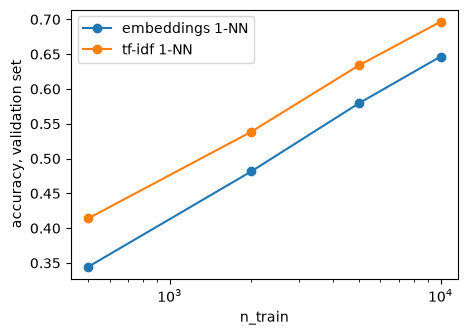

,embeddings 1-NN,tf-idf 1-NN
n_train,,
500,0.344,0.414
2000,0.482,0.538
5000,0.580,0.634
10000,0.646,0.696


In [39]:
rng = np.random.default_rng(0)
heads_tr, truth = train["heading"].to_numpy(), valid["heading"].to_numpy()
curve = []
for n in [500, 2000, 5000, len(train)]:
    idx = rng.choice(len(train), n, replace=False)
    emb = heads_tr[idx][np.argmax(E_va @ E_tr[idx].T, axis=1)]
    v = TfidfVectorizer(sublinear_tf=True).fit(train["description"].iloc[idx])
    sims = v.transform(valid["description"]) @ v.transform(train["description"].iloc[idx]).T
    tf = heads_tr[idx][np.asarray(sims.argmax(axis=1)).ravel()]
    curve.append({"n_train": n, "embeddings 1-NN": np.mean(emb == truth), "tf-idf 1-NN": np.mean(tf == truth)})
curve = pd.DataFrame(curve).set_index("n_train")
curve.plot(marker="o", logx=True, ylabel="accuracy, validation set", figsize=(5, 3.5))
plt.show()
curve.round(3)

TF-IDF is ahead at every size here: the expected advantage of embeddings with few labels does not appear, because with almost 1,000 headings and 500 examples most headings have no example at all. SetFit (Tunstall et al., 2022) showed that sentence-transformers *fine-tuned* on as few as eight examples per class compete with much larger models on tasks with a handful of classes: fine-tuning, not frozen vectors, is what makes embeddings strong classifiers.

## Worked example · How often does a new request find its heading among similar decisions in other languages?

A customs officer in Germany receives a request and looks at the five most similar past decisions. If one of them has the right heading, the search was useful. The share of requests for which this happens is **hit@5**. We measure it twice: over all training decisions, and for non-German requests searched among German decisions only (the cross-lingual case), with embeddings and with TF-IDF.

Next cell: nearest neighbours of all 2,000 validation decisions. `np.argsort(-S, axis=1)[:, :5]` gives the five most similar training decisions per row.

In [40]:
nn = np.argsort(-(E_va @ E_tr.T), axis=1)[:, :5]
print("1-NN accuracy:", round(float(np.mean(heads_tr[nn[:, 0]] == truth)), 3))
print("hit@5:", round(float(np.mean([h in heads_tr[r] for h, r in zip(truth, nn)])), 3))
same_lang = train["language"].to_numpy()[nn] == valid["language"].to_numpy()[:, None]
print("neighbours in the query's language:", round(float(same_lang.mean()), 3))

1-NN accuracy: 0.646
hit@5: 0.78
neighbours in the query's language: 0.971


Almost all neighbours share the query's language: the model places texts of one language closer together than translations. So a cross-lingual search must be asked for explicitly, for example by restricting the documents to one language. Next we do that: non-German requests, German decisions only, embeddings against TF-IDF.

In [41]:
other = (valid["language"] != "de").to_numpy()
truth_other = valid["heading"][other]
nn_emb = np.argsort(-(E_va[other] @ E_tr[german].T), axis=1)[:, :5]
nn_tfidf = np.argsort(-(T_va[other] @ T_de.T).toarray(), axis=1)[:, :5]
for method, nn_x in [("embeddings", nn_emb), ("tf-idf", nn_tfidf)]:
    hit = np.mean([h in heads_de[r] for h, r in zip(truth_other, nn_x)])
    print(f"{method:10s} cross-lingual hit@5 = {hit:.3f}  ({other.sum()} non-German requests)")

embeddings cross-lingual hit@5 = 0.412  (782 non-German requests)
tf-idf     cross-lingual hit@5 = 0.170  (782 non-German requests)


Across languages, embeddings find the right heading among five German decisions far more often than TF-IDF, which can only match shared numbers, brand names and loan words. This is the strength of embeddings on the case study, and the retrieval step that Block 2 and Session 15 build on.

Finally, one request and its neighbours, to read what "similar" means. `NearestNeighbors(metric="cosine")` from scikit-learn does the same search as the matrix product, with distances (1 − cosine).

In [42]:
from sklearn.neighbors import NearestNeighbors

index = NearestNeighbors(n_neighbors=5, metric="cosine").fit(E_tr)
i = 10
print(valid["language"].iloc[i], valid["heading"].iloc[i], valid["description"].iloc[i][:100].replace("\n", " "))
dist, ind = index.kneighbors(E_va[[i]])
for dd, j in zip(dist[0], ind[0]):
    print(f"  {1 - dd:.2f}  {train['language'].iloc[j]}  {train['heading'].iloc[j]}  "
          f"{train['description'].iloc[j][:80].replace(chr(10), ' ')}")

fr 2209 Assortiment conditionné ensemble pour la vente au détail dans un coffret bois, de type plateau apéro
  0.91  fr  3406  Assortiment conditionné pour la vente au détail présenté sur un plateau en fer, 
  0.90  fr  1806  Assortiment de marchandises conditionné dans un coffret en carton pour la vente 
  0.90  fr  3406  Assortiment conditionné pour la vente au détail présenté dans une cage métalliqu
  0.90  fr  4420  Assortiment conditionné pour la vente au détail composé : - d'un plateau en bois
  0.90  fr  8215  Ensemble de marchandises conditionnées pour la vente au détail se présentant sou


## Check your understanding

1. Why can a subword tokeniser represent any word, while `CountVectorizer` cannot? What is the price?
2. Compute the cosine similarity of (1, 0, 1) and (1, 1, 0) by hand.
3. Which model family would you choose for (a) finding decisions similar to a new request, (b) writing a short justification for a proposed heading, (c) translating a Polish description into English?
4. What would go wrong in mean pooling without the attention mask?
5. Embeddings win at cross-lingual search but lose to TF-IDF as classification features. Give one reason for each.

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there is not time for all of them. The code exercises use `model`, `sp_tok`, `gpt_tok`, `decisions`, `train`, `E_tr` and `tfidf` from the cells above, so run the notebook first.

### 1.1 · What is tezgüino?

*Paper · 5 min*

> "A bottle of tezgüino is on the table. Everyone likes tezgüino. Tezgüino makes you drunk. We make tezgüino out of corn." What is it, and which words told you?

*Source:* [Lin (1998), "Automatic retrieval and clustering of similar words" (example after Nida 1975)](https://aclanthology.org/P98-2127/)

*Your answer:*

### 1.2 · Cosine similarity by hand

*Paper · 10 min*

> Three two-dimensional "embeddings": which pair is closest?
>
> a = (2, 1) "Spielzeugauto", b = (3, 2) "voiture jouet", c = (1, 3) "Damenschuhe".
>
> Compute the three cosine similarities. Then add d = (4, 2): what is cos(a, d), and what is the Euclidean distance between a and d? What does this say about the length of an embedding vector?

*Source:* [Jurafsky & Martin, *Speech and Language Processing*, Chapter 5: cosine similarity](https://web.stanford.edu/~jurafsky/slp3/5.pdf)

*Your answer:*

### 1.3 · Tokens per language

*Predict, then Code · 10 min*

> One product description in English, German, Hungarian and Greek (in the starter cell below). Predict the token counts, then count them with the local tokenizer.
>
> Write your four predictions down before you run anything. Then count words and tokens with the e5 tokeniser (`sp_tok.tokenize`) and the GPT-4o tokeniser (`gpt_tok.encode`), and compute tokens per word for each language. Which language would cost the most in an API that bills per token?

*Source:* [Petrov et al. (2023), "Language model tokenizers introduce unfairness between languages"](https://arxiv.org/abs/2305.15425)

In [43]:
# starter: the same toy car in four languages (translations by the course team)
texts_4 = {
    "en": "Toy car for children, made of plastic, with four wheels and a battery-powered electric motor.",
    "de": "Spielzeugauto für Kinder aus Kunststoff, mit vier Rädern und einem batteriebetriebenen Elektromotor.",
    "hu": "Gyermekeknek szánt műanyag játékautó négy kerékkel és elemmel működő elektromos motorral.",
    "el": "Παιχνίδι αυτοκίνητο για παιδιά, από πλαστικό, με τέσσερις τροχούς και ηλεκτρικό κινητήρα που λειτουργεί με μπαταρίες.",
}

*Your predictions (before running code):*

### 1.4 · Swap the model name

*Code · 10 min*

> The Hugging Face pattern section showed that every model comes with its own tokeniser and that `AutoTokenizer.from_pretrained(name)` loads it. Tokenise the German and the French description below with the tokenisers of three models: `intfloat/multilingual-e5-small`, `google-bert/bert-base-german-cased` and `distilbert/distilbert-base-uncased-finetuned-sst-2-english`. Change only the name. Count the tokens and look at the pieces: which tokeniser splits the French text into the most pieces, which one loses the capital letters, and why? Which of the three models would you use for descriptions in 23 languages?

*Source:* original exercise for this course; background: [Hugging Face LLM Course, chapter 2: tokenizers](https://huggingface.co/learn/llm-course/chapter2/4)

In [44]:
# starter: two descriptions of women's leather shoes
descriptions_2 = {
    "de": "Damenstiefel mit Oberteil aus Rindleder und Laufsohle aus Gummi",
    "fr": "Chaussures pour femmes, dessus en cuir, semelle en caoutchouc",
}
names = ["intfloat/multilingual-e5-small",
         "google-bert/bert-base-german-cased",
         "distilbert/distilbert-base-uncased-finetuned-sst-2-english"]

### 1.5 · Same goods, different languages

*Code · 10 min*

> Take the decisions of two headings, 9503 (toys) and 6404 (footwear with textile uppers), and draw two decisions per heading in each of German, French and Czech (12 decisions, `random_state=0`, from `decisions`). Embed them with the `"passage: "` prefix and compute the 12 × 12 similarity matrix. Compare the mean similarity of pairs with the same heading but a different language with that of pairs with the same language but a different heading. Read the English `keywords` of the decisions to check what they are about. Which matters more for the model: the goods or the language?

*Source:* original exercise for this course; background: [Sentence-Transformers documentation: multilingual models](https://sbert.net/examples/sentence_transformer/training/multilingual/README.html)

### 1.6 · Search the French decisions

*Pairs · 15 min*

> Build a search over the **French** decisions of `train` only (`train["language"] == "fr"`), with the embeddings `E_tr` and with TF-IDF. Search with two German queries and one English query of your own (for example a product you own), and judge the top 5 of each method with the English `keywords`. Then find one query for which TF-IDF gives the more useful top 5 and explain why.

*Source:* original exercise for this course; background: [Sentence-Transformers documentation: semantic search](https://sbert.net/examples/sentence_transformer/applications/semantic-search/README.html)

### 1.7 · Clusters of toys

*Code · 15 min*

> *Stretch:* Cluster the training decisions of chapter 95 (toys, games and sports equipment; `train["chapter"] == "95"`) with k-means on their embeddings, for k = 4 and k = 8. Cross-tabulate the clusters against `heading` and against `language`, and compute the adjusted Rand index with the headings. Do the clusters reflect goods or languages?

*Source:* original exercise for this course; background: [scikit-learn user guide: clustering performance evaluation](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation)

## Debrief (15 min)

- **Compare** two similarity tables from 1.5: did language or goods dominate? Look for pairs who compared similarities with a fixed threshold such as 0.5 instead of with each other; for e5 almost every pair is above 0.7.
- **Collect** the queries from 1.6 where TF-IDF won and look for what they share (brand names, codes, loan words). This is the argument for hybrid search in Session 15.
- **Typical mistakes:** forgetting the norms in 1.2 and calling a·d = 10 "most similar"; predicting German as the most expensive language in 1.3 because of its long words; forgetting the `"query: "`/`"passage: "` prefixes in 1.5 and 1.6.
- **Bridge to Block 2:** encoders turn text into vectors. Decoders generate text one token at a time; Block 2 asks one to choose a heading among candidates proposed by a trained classifier, and compares it with that classifier.

## Further reading

- Alammar, J. (2018). *The Illustrated Transformer*. https://jalammar.github.io/illustrated-transformer/
- Hugging Face. *LLM Course*, chapters 1 (transformer models), 2 (using transformers) and 6 (tokenisers). https://huggingface.co/learn/llm-course (Apache-2.0; the sections on byte-pair encoding, one model of each family and inside the tokeniser are adapted from it)
- Reimers, N. and Gurevych, I. (2019). Sentence-BERT: sentence embeddings using Siamese BERT-networks. *EMNLP-IJCNLP 2019*. Documentation and examples (Apache-2.0; the section on retrieve and re-rank is adapted from them): https://sbert.net/
- OpenAI Cookbook (MIT): *How to count tokens with tiktoken* (encodings compared) and *K-means clustering* (the t-SNE map). https://cookbook.openai.com/
- Wang, L. et al. (2024). Multilingual E5 text embeddings: a technical report. arXiv:2402.05672. https://arxiv.org/abs/2402.05672
- Muennighoff, N., Tazi, N., Magne, L. and Reimers, N. (2023). MTEB: massive text embedding benchmark. *EACL 2023*. https://huggingface.co/spaces/mteb/leaderboard
- Vaswani, A. et al. (2017). Attention is all you need. *NeurIPS 2017*. https://arxiv.org/abs/1706.03762
- Raffel, C. et al. (2020). Exploring the limits of transfer learning with a unified text-to-text transformer (T5). *JMLR* 21(140). https://jmlr.org/papers/v21/20-074.html
- Sennrich, R., Haddow, B. and Birch, A. (2016). Neural machine translation of rare words with subword units. *ACL 2016*. https://aclanthology.org/P16-1162/
- Petrov, A., La Malfa, E., Torr, P. H. S. and Bibi, A. (2023). Language model tokenizers introduce unfairness between languages. *NeurIPS 2023*. https://arxiv.org/abs/2305.15425
- Mikolov, T., Chen, K., Corrado, G. and Dean, J. (2013). Efficient estimation of word representations in vector space. arXiv:1301.3781.
- Firth, J. R. (1957). A synopsis of linguistic theory 1930–1955. In *Studies in Linguistic Analysis*. Blackwell.
- Bolukbasi, T. et al. (2016). Man is to computer programmer as woman is to homemaker? Debiasing word embeddings. *NeurIPS 2016*. https://arxiv.org/abs/1607.06520
- Jain, S. and Wallace, B. C. (2019). Attention is not explanation. *NAACL 2019*. https://aclanthology.org/N19-1357/
- Grootendorst, M. (2022). BERTopic: neural topic modeling with a class-based TF-IDF procedure. arXiv:2203.05794.
- Tunstall, L. et al. (2022). Efficient few-shot learning without prompts (SetFit). arXiv:2209.11055.
- 3Blue1Brown. *Transformers, the tech behind LLMs* (video lessons). https://www.3blue1brown.com/lessons/gpt
- Extras of this block: [01 tokenisers](extras/01-hf-course-tokenizers.ipynb), [02 BPE](extras/02-hf-course-bpe-tokenization.ipynb), [03 counting tokens](extras/03-openai-cookbook-count-tokens.ipynb), [04 pipelines](extras/04-hf-course-transformer-pipelines.ipynb), [05 retrieve and re-rank](extras/05-sbert-retrieve-rerank-wikipedia.ipynb), [06 clustering](extras/06-openai-cookbook-clustering.ipynb); provenance in [extras/README.md](extras/README.md).

*Course material, CC BY 4.0; adapted sections keep the licence of their source (Apache-2.0 or MIT, named at each section). Models: intfloat/multilingual-e5-small (MIT), sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 (Apache-2.0), MoritzLaurer/mDeBERTa-v3-base-mnli-xnli (MIT), google-bert/bert-base-german-cased (MIT), distilbert/distilbert-base-uncased-finetuned-sst-2-english (Apache-2.0), openai-community/gpt2 (MIT), Qwen/Qwen2.5-0.5B-Instruct (Apache-2.0), google-t5/t5-small (Apache-2.0), cross-encoder/ms-marco-MiniLM-L6-v2 (Apache-2.0). Data: European Commission, EBTI database (Commission Decision 2011/833/EU).*